## **Forward solve and inversion**

In this notebook, we show the end-to-end experiment workflow, where we invert for five tissue conductivity parameteres from noisy sEMG readings placed on the skin surface of the limb, which is modelled as a cylinder. Everything computational is imported from `neuralphysics`. Derivations are in `docs/` (this has not been written yet) and correctness checks in `tests/`.

In [1]:
# import the whole API the experiment needs

import platform
from dataclasses import replace

import math
import platform
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
from matplotlib.ticker import FuncFormatter
import numpy as np
import scipy
import torch

import neuralphysics
from IPython.display import HTML
from scipy.optimize import minimize

from neuralphysics import (
    DEFAULT,
    CoefficientHierarchy,
    ElectrodeArray,
    Observation,
    add_measurement_noise,
    configure,
    dipole_centres,
    forward,
    gaussian_dipole,
    grid_at,
    impose_net_zero_CSD,
    interfaces_from_logits,
    laplacian_metric_3D,
    logits_from_interfaces,
    trapezoid_weight_field,
    viz,
)

In [2]:
print(configure())
print(f"neuralphysics {neuralphysics.__version__} | torch {torch.__version__} | "
      f"numpy {np.__version__} | scipy {scipy.__version__} | python {platform.python_version()}")
print(f"default dtype {torch.get_default_dtype()} | torch threads {torch.get_num_threads()} | "
      f"{platform.platform()}")

{'dtype': 'torch.float64', 'seed': 42}
neuralphysics 0.1.0 | torch 2.5.1 | numpy 1.26.4 | scipy 1.17.1 | python 3.11.15
default dtype torch.float64 | torch threads 4 | macOS-26.6.1-arm64-arm-64bit


In [3]:
NUM_CYCLES = 8
NOISE_PERCENT = 5.0 # measurement noise, as a percentage of the clean field's RMS


gcfg, tissue = DEFAULT.grid, DEFAULT.tissue # local alias bounding
solver = replace(DEFAULT.solver, num_cycles=NUM_CYCLES)

USE_TIKHONOV = False        # the penalty biases the weakly-determined parameters
TIKHONOV_LAMBDA = 1e-7      # only consulted when USE_TIKHONOV is True

MAX_ITERS = 1000            # L-BFGS-B iteration budget

inv = replace(DEFAULT.inversion, noise_percent=NOISE_PERCENT,
              use_tikhonov=USE_TIKHONOV, tikhonov_lambda=TIKHONOV_LAMBDA,
              max_iters=MAX_ITERS)

penalty = f"Tikhonov lambda = {inv.tikhonov_lambda:g}" if inv.use_tikhonov else "no penalty"

# the default values
print(f"grid     N = {gcfg.N}, L = {gcfg.L}, h = {gcfg.h:.5f}, levels {gcfg.levels()}")
print(f"solver   {solver.num_cycles} V-cycles, nu = ({solver.nu_pre}, {solver.nu_post}), "
      f"omega = {solver.omega:.4f}, {solver.base_iters} base iterations")
print(f"data     {inv.noise_percent}% noise (seed {inv.noise_seed}), "
      f"electrode coverage {inv.electrode_coverage:.2f}")
print(f"inverse  L-BFGS-B, <= {inv.max_iters} iterations, {penalty}")

grid     N = 65, L = 1.0, h = 0.01562, levels [65, 33, 17, 9]
solver   8 V-cycles, nu = (2, 2), omega = 0.6667, 50 base iterations
data     5.0% noise (seed 0), electrode coverage 1.00
inverse  L-BFGS-B, <= 1000 iterations, no penalty


In [4]:
print(f"{'layer':8s} {'r/R':>12s} {'sigma_T':>8s} {'sigma_L':>8s}   source")
r_lo = 0.0
for nm, r_hi in zip(tissue.layer_names, tissue.interfaces + (0.5,)):
    sT, sL = tissue.sigma_layers[nm]
    print(f"{nm:8s} {f'{r_lo:.2f}-{r_hi:.2f}':>12s} {sT:8.2f} {sL:8.2f}   "
          f"{'PROVISIONAL' if nm in tissue.provisional else 'Mesin (2013)'}")
    r_lo = r_hi

print(f"\nanisotropic layers: {sorted(tissue.anisotropic_layers)}")
print(f"recovering {len(inv.sigma_init)} parameters from {dict(inv.sigma_init)}")

layer             r/R  sigma_T  sigma_L   source
bone        0.00-0.15     0.02     0.02   PROVISIONAL
muscle      0.15-0.42     0.09     0.40   Mesin (2013)
fat         0.42-0.48     0.04     0.04   Mesin (2013)
skin        0.48-0.50     0.05     0.05   PROVISIONAL

anisotropic layers: ['muscle']
recovering 5 parameters from {'bone': 0.05, 'muscle_T': 0.05, 'muscle_L': 0.2, 'fat': 0.02, 'skin': 0.1}


In [5]:
grid = grid_at(gcfg.N, L=gcfg.L, z_zeta=gcfg.z_zeta)
det, rim = grid.det_J, grid.rim_stats(tissue.shell_norm)

print(grid)
print(f"type(grid) = {type(grid)}")
print(f"rim radius  mean {rim['mean']:.5f}, spread {rim['spread']:.2e} "
      f"({rim['spread_in_h']:.3f} h)")
print(f"det(J)      min {float(det.min()):.5f}, max {float(det.max()):.5f}")
print("interfaces  " + ",  ".join(
    f"{a}/{b} {R:.2f} -> {grid.physical_shell_radius(R, tissue.shell_norm):.4f}"
    for a, b, R in zip(tissue.layer_names, tissue.layer_names[1:], tissue.interfaces)))

CylinderGrid(n=65, L=1.0, smoothing=SmoothingPolicy(iterations=100, del_t=0.2), z_zeta=1.0, mapped=True)
type(grid) = <class 'neuralphysics.grid.CylinderGrid'>
rim radius  mean 0.50144, spread 1.62e-02 (1.035 h)
det(J)      min 0.11417, max 1.11886
interfaces  bone/muscle 0.15 -> 0.1463,  muscle/fat 0.42 -> 0.4179,  fat/skin 0.48 -> 0.4805


det(J) > 0 everywhere is the mesh-validity gate. The Jacobian determinant is the local volume scaling of the coordinate change; if it touches zero, then the map has folded and the metric coefficients blow up, making the finite-volume operator meaningless.

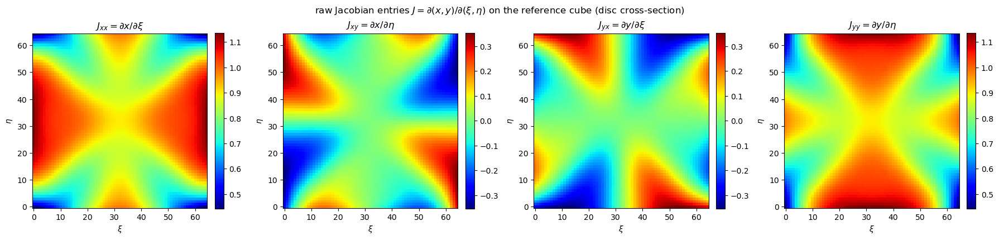

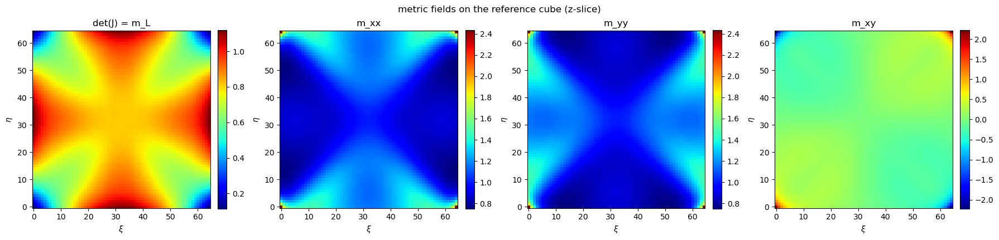

In [6]:
# look at what the Laplacian mesh smoothing produced
fig_jacobian = viz.plot_jacobian_fields(grid)
fig_metric = viz.plot_metric_fields(grid)

The Jacobian panel shows the four signed partials of the map $\Phi:(\xi,\eta)\mapsto(x,y)$, so we can check the map; the metric panel shows the three transverse coefficients plus $\det J$, which are what the operator consumes.

With $J = \begin{pmatrix} a & b \\ c & d\end{pmatrix}$, and $a = \partial x/\partial\xi$, the module assembles,

$$m_{xx} = \frac{z_\zeta}{\det J}(b^2 + d^2), \quad m_{yy} = \frac{z_\zeta}{\det J}(a^2 + c^2), \quad m_{xy} = -\frac{z_\zeta}{\det J}(ab + cd), \quad m_L = \frac{\det J}{z_\zeta}.$$

Squaring is what causes the metric panel to be sign-agnostic, and why $m_{xx}$ is built from the $\eta$-derivatives instead of $\xi$-ones, as it comes from inverting $J$, not from transposing it.

Note that the map has no closed form, hence, so $J$ is measured. The smoothed square-to-disc composite exists only as node positions, so every entry is a central difference approximation, $f'(t)\approx (f(t+h)-f(t-h))/2h$, taken with respect to the structured grid spacing $h = 1/(N-1)$ NOT the physical (cylindrical) grid spacing!

In [7]:
# we need a reference with what values we use the for the respective radii/areas/volumes
# and a proper reference for the conductivity values

bone       349 nodes/slice    8.3%
muscle    2492 nodes/slice   59.0%
fat        884 nodes/slice   20.9%
skin       500 nodes/slice   11.8%


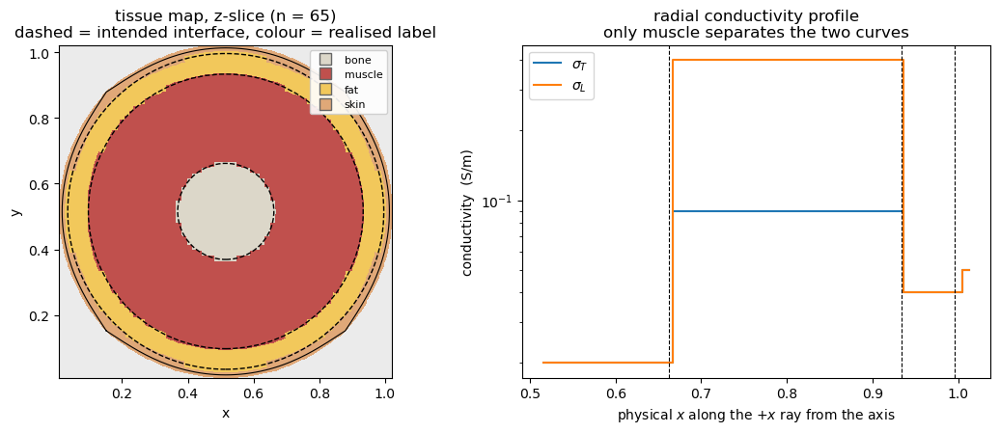

In [8]:
# visualising a cross section of the limb and how the conductivity sigma varies as we go along the radius from the centre

fig_tissue = viz.plot_tissue_map(grid, tissue)

idx = tissue.layer_index(grid)
counts = torch.bincount(idx[:, :, 0].reshape(-1), minlength=tissue.n_layers)
for k, nm in enumerate(tissue.layer_names):
    print(f"{nm:8s} {int(counts[k]):5d} nodes/slice  {100 * int(counts[k]) / int(counts.sum()):5.1f}%")

In [9]:
width = 0.05
# (r_blob_norm, angle_deg) per source. Radius is the informative axis -- the limb is
# rotationally symmetric, so two sources at one radius and different angles are
# rotated copies carrying no new information. The angle only keeps the blobs apart.
# 0.250 sits near the bone/muscle interface, 0.312 near muscle/fat; the clearance
# rule confines both to [0.246, 0.316].

# The clearance rule confines r_blob_norm to [0.246, 0.316], so a third source cannot
# be placed anywhere new in radius -- only between the two you have. That band is the
# whole design space, and it is why a third source has so little left to add.
R3, A3 = 0.281, 90.0                    # None disables the third source
SOURCE_SPECS = ((0.250, 0.0), (0.312, 180.0)) + (((R3, A3),) if R3 is not None else ())

sources = [gaussian_dipole(grid, tissue, width=width, r_blob_norm=r, angle_deg=a)
           for r, a in SOURCE_SPECS]
centres = [dipole_centres(grid, tissue, r_blob_norm=r, angle_deg=a)
           for r, a in SOURCE_SPECS]
I_true = sources[0]
W = trapezoid_weight_field(grid.n)

for s, (I, c) in enumerate(zip(sources, centres)):
    print(f"source {s}: r = {c['r_blob']:.4f} at {c['angle_deg']:.0f} deg, clearance "
          f"{min(c['r_blob'] - c['r_inner'], c['r_outer'] - c['r_blob']):.4f} vs "
          f"2w = {2 * width:.2f}, peak {float(I.abs().max()):.4f}, "
          f"W.I = {float((W * I).sum()):.2e}")
print(f"muscle spans [{centres[0]['r_inner']:.4f}, {centres[0]['r_outer']:.4f}], "
      f"z source {centres[0]['cz_source']:.3f}, sink {centres[0]['cz_sink']:.3f}, "
      f"w/h = {width / grid.h:.2f}")

source 0: r = 0.2507 at 0 deg, clearance 0.1045 vs 2w = 0.10, peak 0.9893, W.I = -4.47e-16
source 1: r = 0.3129 at 180 deg, clearance 0.1050 vs 2w = 0.10, peak 0.9871, W.I = -1.29e-17
source 2: r = 0.2818 at 90 deg, clearance 0.1356 vs 2w = 0.10, peak 0.9886, W.I = -1.94e-16
muscle spans [0.1463, 0.4179], z source 0.370, sink 0.630, w/h = 3.20


In [10]:
# --- superposition switch ----------------------------------------------------
# Both motor units fire together and the array records ONE field, instead of two
# separately observed excitations. The operator is linear in the source, so the clean
# composite field is exactly phi_1 + phi_2 -- what changes is the DATA, not the physics.
# Two observations append rows to the Jacobian; one observation of the sum does not, and
# there the two sources' sensitivities can cancel rather than stack.
#
# Everything downstream iterates over `sources` and `observations`, so this single
# reassignment is the whole experiment. Set False to reproduce the two-solve run.
SUPERPOSE = True

sources_sep = list(sources)                # kept for the linearity check
if SUPERPOSE:
    sources = [impose_net_zero_CSD(sum(sources_sep))]
    I_true = sources[0]

print(f"{len(sources)} observation(s), {'superposed' if SUPERPOSE else 'separate'} | "
      f"I peak {float(I_true.abs().max()):.4f}, W.I = {float((W * I_true).sum()):.2e}")

1 observation(s), superposed | I peak 0.9893, W.I = -5.73e-16


In [11]:
# w.T I = 0 is a necessary condition for the system to have any solution at all i.e. left null space must be empty.

In [12]:
# the face coefficient tensor has shape (6,n,n,n) ie. six faces per node.
# the finite-volume operator is assembled in flux form, so each node's equation is a sum of fluxes through its six faces,
# and the homogeneous Neumann condition is imposed by omitting boundary faces from the sum
# recall that the conductivities are harmonic means - where the interface physics lives
# and the metric fields are arithmetic means
# the product of both of these make up our face coefficients

In [13]:
SOFT_TRUTH = True # diagnostic: generate the data with the membership the inversion uses i.e. soft labels

if SOFT_TRUTH:
    coeff_true = CoefficientHierarchy.from_vectors(
        gcfg, tissue, *tissue.sigma_vectors(),
        interfaces=torch.as_tensor(tissue.interfaces), epsilon=inv.epsilon)
else:
    coeff_true = CoefficientHierarchy.from_truth(gcfg, tissue)

print(f"data model: {'soft membership, epsilon = ' + format(inv.epsilon, '.5f') if SOFT_TRUTH else 'hard labels'}")
print(f"levels {coeff_true.levels} | n_fine {coeff_true.n_fine} | "
      f"requires_grad {coeff_true.requires_grad}")

print(f"levels {coeff_true.levels} | n_fine {coeff_true.n_fine} | "
      f"requires_grad {coeff_true.requires_grad}")
for n in coeff_true.levels:
    f = coeff_true.faces[n]
    print(f"  n = {n:3d}  faces {tuple(f.shape)}  sigma_T {tuple(coeff_true.sigma_T[n].shape)}  "
          f"face coeff range [{float(f.min()):.4f}, {float(f.max()):.4f}]")

data model: soft membership, epsilon = 0.00391
levels (65, 33, 17, 9) | n_fine 65 | requires_grad False
levels (65, 33, 17, 9) | n_fine 65 | requires_grad False
  n =  65  faces (6, 65, 65, 65)  sigma_T (65, 65, 65)  face coeff range [0.0057, 0.3848]
  n =  33  faces (6, 33, 33, 33)  sigma_T (33, 33, 33)  face coeff range [0.0076, 0.3832]
  n =  17  faces (6, 17, 17, 17)  sigma_T (17, 17, 17)  face coeff range [0.0126, 0.3673]
  n =   9  faces (6, 9, 9, 9)  sigma_T (9, 9, 9)  face coeff range [0.0173, 0.3603]


In [14]:
type(coeff_true)

neuralphysics.hierarchy.CoefficientHierarchy

In [15]:
A = lambda f: laplacian_metric_3D(f, grid.h, coeff_true.faces[grid.n],
                                  coeff_true.metric[grid.n], coeff_true.sigma_T[grid.n])

# measure how fast our v-cycle converges
prev = None
for k in range(1, solver.num_cycles + 1):          # a fixed count, not a tolerance
    phi_true = forward(I_true, coeff_true, gcfg, solver, num_cycles=k)
    r = float((I_true - A(phi_true)).norm() / I_true.norm())
    print(f"  cycle {k}: ||I - A phi|| / ||I|| = {r:.4e}"
          + ("" if prev is None else f"   factor {r / prev:.3f}"))
    prev = r

print(f"\nphi range [{float(phi_true.min()):.3e}, {float(phi_true.max()):.3e}], "
      f"gauge W.phi = {float((W * phi_true).sum()):.2e}")

  cycle 1: ||I - A phi|| / ||I|| = 3.6371e-01
  cycle 2: ||I - A phi|| / ||I|| = 1.7186e-01   factor 0.473
  cycle 3: ||I - A phi|| / ||I|| = 9.0026e-02   factor 0.524
  cycle 4: ||I - A phi|| / ||I|| = 4.9343e-02   factor 0.548
  cycle 5: ||I - A phi|| / ||I|| = 2.7959e-02   factor 0.567
  cycle 6: ||I - A phi|| / ||I|| = 1.6223e-02   factor 0.580
  cycle 7: ||I - A phi|| / ||I|| = 9.6018e-03   factor 0.592
  cycle 8: ||I - A phi|| / ||I|| = 5.7750e-03   factor 0.601

phi range [-7.239e-03, 7.239e-03], gauge W.phi = -1.03e-15


In [16]:
if SUPERPOSE:
    phi_parts = [forward(I, coeff_true, gcfg, solver) for I in sources_sep]
    rel = float((phi_true - sum(phi_parts)).norm() / phi_true.norm())
    print(f"linearity  ||phi(I_1 + I_2) - (phi_1 + phi_2)|| / ||phi|| = {rel:.2e}")

linearity  ||phi(I_1 + I_2) - (phi_1 + phi_2)|| / ||phi|| = 9.72e-17


In [17]:
array = ElectrodeArray(coverage_target=inv.electrode_coverage,
                       use_surface=inv.use_surface_electrodes)
mask_nodes = array.mask(grid.n)

observations = []
for s, I in enumerate(sources):
    phi_s = phi_true if s == 0 else forward(I, coeff_true, gcfg, solver)
    phi_obs, noise_stats = add_measurement_noise(phi_s, inv.noise_percent,
                                                 inv.noise_seed + s)
    observations.append(Observation(phi=phi_obs, mask=mask_nodes, grid=grid))
    print(f"noise  source {s}: {inv.noise_percent:.1f}% of RMS {noise_stats['rms']:.3e} -> "
          f"std {noise_stats['noise_std']:.3e}, realised SNR {noise_stats['snr']:.2f}")

obs = observations[0]      # the field and residual figures are drawn for source 1
print(f"array  step {array.step}, coverage {array.coverage(grid.n):.3f}, "
      f"{int(obs.mask.sum())} electrodes of {grid.n ** 3} nodes")

noise  source 0: 5.0% of RMS 1.427e-03 -> std 7.133e-05, realised SNR 20.00
array  step 1, coverage 1.000, 16640 electrodes of 274625 nodes


In [18]:
noise_stats

{'rms': 0.001426600661657084,
 'noise_std': 7.13300330828542e-05,
 'snr': 20.001553241005293}

In [19]:
# the slider allows us to walk along the fibre-axis (longitudinal direction)
# and view the cross-sections as we go along the limb
fig_anim, anim = viz.animate_slices(sources, [o.phi for o in observations],
                                    grid, tissue, noise_percent=inv.noise_percent)
plt.close(fig_anim)
HTML(anim.to_jshtml())

In [20]:
param_names = list(inv.sigma_init)
sigma_true = torch.tensor([tissue.sigma_layers["bone"][0],
                           tissue.sigma_layers["muscle"][0],
                           tissue.sigma_layers["muscle"][1],
                           tissue.sigma_layers["fat"][0],
                           tissue.sigma_layers["skin"][0]])
rho_ref = torch.log(torch.tensor([inv.sigma_init[nm] for nm in param_names]))

n_sigma = len(param_names)
R_OUTER = tissue.interfaces[-1]        # fat/skin surface: fixed, not recovered
LIMB_RADIUS_MM = 24.0                  # 0.5 normalised units at the rim

u_true = logits_from_interfaces(tissue.interfaces)
u_ref = logits_from_interfaces(inv.radii_init + (R_OUTER,))
theta_true = torch.cat([torch.log(sigma_true), u_true])
theta_ref = torch.cat([rho_ref, u_ref])


def unpack(theta):
    """(7,) parameters -> (sigma_T, sigma_L, interface radii).

    The first five are log-conductivities. bone, fat and skin appear in both vectors as
    the same tensor element, so an isotropic tissue's gradient accumulates into one
    scalar; muscle splits into T and L.

    The last two are softmax logits for the two inner interfaces. They are
    unconstrained: any real pair gives 0 < R_1 < R_2 < R_OUTER, so L-BFGS-B needs no
    bounds and no ordering constraint.
    """
    s = theta[:n_sigma].exp()
    return (torch.stack([s[0], s[1], s[3], s[4]]),      # bone, muscle_T, fat, skin
            torch.stack([s[0], s[2], s[3], s[4]]),      # bone, muscle_L, fat, skin
            interfaces_from_logits(theta[n_sigma:], R_OUTER))


def thicknesses_mm(interfaces):
    """Interface radii -> the four layer thicknesses in mm, skin closed off at the rim.

    A thickness is the anatomical quantity; a radius is a coordinate. Skin appears here
    even though it is not recovered, because it is the difference between R_OUTER and
    the rim and so is the one thickness fixed by assumption.
    """
    R = torch.as_tensor(interfaces).reshape(-1)
    edges = torch.cat([torch.zeros_like(R[:1]), R, torch.full_like(R[:1], 0.5)])
    return torch.diff(edges) * (LIMB_RADIUS_MM / 0.5)


sT_ref, sL_ref = tissue.sigma_vectors()
sT_chk, sL_chk, R_chk = unpack(theta_true)
print(f"layers {tissue.layer_names} | params {param_names} + logits u_1, u_2")
print(f"unpack(theta_true) reproduces the tissue table: "
      f"{torch.allclose(sT_chk, sT_ref) and torch.allclose(sL_chk, sL_ref)}")
print(f"          and round-trips the geometry: "
      f"{torch.allclose(R_chk, torch.as_tensor(tissue.interfaces))}")
print(f"start sigma {[f'{v:.3f}' for v in rho_ref.exp().tolist()]}")
print(f"start  {[f'{v:.2f}' for v in thicknesses_mm(unpack(theta_ref)[2]).tolist()]} mm")
print(f"true   {[f'{v:.2f}' for v in thicknesses_mm(tissue.interfaces).tolist()]} mm")

layers ('bone', 'muscle', 'fat', 'skin') | params ['bone', 'muscle_T', 'muscle_L', 'fat', 'skin'] + logits u_1, u_2
unpack(theta_true) reproduces the tissue table: True
          and round-trips the geometry: True
start sigma ['0.050', '0.050', '0.200', '0.020', '0.100']
start  ['8.00', '11.50', '3.50', '1.00'] mm
true   ['7.00', '13.00', '3.00', '1.00'] mm


In [21]:
mask = obs.mask
phi_obs_norm = float(torch.sqrt(sum((o.phi[mask] ** 2).sum() for o in observations)))

loss_history, data_loss_history, reg_loss_history = [], [], []
sigma_history, interface_history, geometry_snapshots = [], [], []
phi_snapshots = []

print(f"{int(mask.sum())} electrode nodes | ||phi_obs|| on the mask = {phi_obs_norm:.4e}")
print(f"recovering {n_sigma} conductivities and 2 interface radii, "
      f"{n_sigma + 2} parameters in all")

16640 electrode nodes | ||phi_obs|| on the mask = 1.4833e-01
recovering 5 conductivities and 2 interface radii, 7 parameters in all


In [22]:
# Marginal value of a third source, measured by the Gauss-Newton Hessian at the truth
# rather than by a full inversion: this is the same quantity as the source-placement
# table, so a third radius can be priced without running the optimiser at each one.
# 14 solves per design (central differences on seven parameters).

FD = 1e-4
R3_SWEEP = (0.250, 0.265, 0.281, 0.298, 0.312)


def _fields(theta, srcs):
    with torch.no_grad():
        sT_vec, sL_vec, R = unpack(theta)
        c = CoefficientHierarchy.from_vectors(gcfg, tissue, sT_vec, sL_vec,
                                              interfaces=R, epsilon=inv.epsilon)
        return [forward(I, c, gcfg, solver) for I in srcs]


def design_covariance(srcs):
    """(cond H, worst-direction 1-sigma, per-parameter 1-sigma) for one observation set.

    Rows are whitened by each observation's own noise std, so designs with different
    field magnitudes are compared on equal measurement quality, not equal raw residual.
    """
    scales = [(inv.noise_percent / 100.0) * float(p.pow(2).mean().sqrt())
              for p in _fields(theta_true, srcs)]
    cols = []
    for p in range(len(theta_true)):
        tp, tm = theta_true.clone(), theta_true.clone()
        tp[p] += FD
        tm[p] -= FD
        hi, lo = _fields(tp, srcs), _fields(tm, srcs)
        cols.append(torch.cat([((a - b)[mask]) / (2 * FD * s)
                               for a, b, s in zip(hi, lo, scales)]))
    J = torch.stack(cols, 1)
    H = J.T @ J
    C = torch.linalg.inv(H)
    ev = torch.linalg.eigvalsh(H)
    return (float(ev.max() / ev.min()), float(C.diagonal().max().sqrt() * 0 +
            torch.linalg.eigvalsh(C).max().sqrt()), C.diagonal().sqrt())


def build(specs):
    return [gaussian_dipole(grid, tissue, width=width, r_blob_norm=r, angle_deg=a)
            for r, a in specs]


base = ((0.250, 0.0), (0.312, 180.0))
designs = {"separate, 2": build(base),
           "superposed, 2": [impose_net_zero_CSD(sum(build(base)))]}
for r3 in R3_SWEEP:
    designs[f"superposed, 3 @ {r3:.3f}"] = [
        impose_net_zero_CSD(sum(build(base + ((r3, 90.0),))))]

print(f"{'design':>24s} {'cond H':>10s} {'worst 1-sig':>12s}  "
      + "  ".join(f"{nm:>9s}" for nm in param_names))
ref = None
for name, srcs in designs.items():
    cond, worst, sig1 = design_covariance(srcs)
    if ref is None:
        ref = worst
    print(f"{name:>24s} {cond:10.4g} {worst:12.4f}  "
          + "  ".join(f"{100 * float(v):8.1f}%" for v in sig1[:len(param_names)])
          + f"   x{worst / ref:.2f} vs separate")

                  design     cond H  worst 1-sig       bone   muscle_T   muscle_L        fat       skin
             separate, 2  7.966e+04       0.1016       8.8%       0.9%       1.3%       8.9%       4.6%   x1.00 vs separate
           superposed, 2  1.283e+06       0.5344      52.5%       1.5%       3.1%      13.3%       7.3%   x5.26 vs separate
   superposed, 3 @ 0.250   2.32e+05       0.2114      19.8%       1.9%       2.8%      17.9%       9.8%   x2.08 vs separate
   superposed, 3 @ 0.265  2.161e+05       0.2029      17.7%       1.9%       2.5%      17.8%       9.5%   x2.00 vs separate
   superposed, 3 @ 0.281  2.118e+05       0.2001      17.1%       1.8%       2.3%      17.4%       9.0%   x1.97 vs separate
   superposed, 3 @ 0.298  2.261e+05       0.2062      18.8%       1.7%       2.3%      16.4%       8.3%   x2.03 vs separate
   superposed, 3 @ 0.312  2.825e+05       0.2303      21.6%       1.6%       2.3%      15.2%       7.6%   x2.27 vs separate


In [23]:
def objective(theta_np, snapshot_interval = 10):
    """(7,) numpy parameters -> (J, dJ/dtheta), the (fun, jac) pair scipy wants.

    The hierarchy is now rebuilt with soft membership at the current radii, so the
    same backward pass that returns dJ/dsigma returns dJ/du. That derivative is a
    shape derivative -- a boundary integral weighted by the conductivity jump --
    obtained with no new derivation.
    """
    theta = torch.tensor(theta_np, dtype=torch.float64, requires_grad=True)
    sT_vec, sL_vec, R = unpack(theta)

    coeff = CoefficientHierarchy.from_vectors(gcfg, tissue, sT_vec, sL_vec,
                                              interfaces=R, epsilon=inv.epsilon)
    preds = [forward(I, coeff, gcfg, solver) for I in sources]

    data_loss = sum(0.5 * ((p - o.phi)[mask] ** 2).sum()
                    for p, o in zip(preds, observations))
    reg_loss = (0.5 * inv.tikhonov_lambda * ((theta[:n_sigma] - rho_ref) ** 2).sum()
                if inv.use_tikhonov else torch.zeros((), dtype=data_loss.dtype))
    loss = data_loss + reg_loss
    loss.backward()

    k = len(loss_history)
    loss_history.append(loss.item())
    data_loss_history.append(data_loss.item())
    reg_loss_history.append(reg_loss.item())
    sigma_history.append(theta[:n_sigma].detach().exp().clone())
    interface_history.append(R.detach().clone())
    geometry_snapshots.append((k, sT_vec.detach().clone(), R.detach().clone()))

    if k % snapshot_interval == 0:
        rel = float(torch.sqrt(sum(((p.detach() - o.phi)[mask] ** 2).sum()
                                   for p, o in zip(preds, observations))) / phi_obs_norm)
        phi_snapshots.append((k, preds[0].detach().clone(), rel))

    if k % 5 == 0:
        s = theta[:n_sigma].detach().exp()
        print(f" eval {k:3d}: J = {loss.item():.4e}  (data {data_loss.item():.4e}"
              f" + reg {reg_loss.item():.2e})   "
              + "  ".join(f"{nm} = {v:.4f}" for nm, v in zip(param_names, s)))
        print(f"           thickness/mm "
              + "  ".join(f"{nm} = {v:.2f}" for nm, v
                          in zip(tissue.layer_names, thicknesses_mm(R.detach()))))

    return loss.item(), theta.grad.detach().numpy().copy()

In [24]:
f0, g0 = objective(theta_ref.numpy())
print(f"||dJ/drho|| = {np.linalg.norm(g0[:n_sigma]):.4e}, "
      f"||dJ/du|| = {np.linalg.norm(g0[n_sigma:]):.4e}, "
      f"ratio {np.linalg.norm(g0[n_sigma:]) / np.linalg.norm(g0[:n_sigma]):.3f}")

 eval   0: J = 9.6906e-03  (data 9.6906e-03 + reg 0.00e+00)   bone = 0.0500  muscle_T = 0.0500  muscle_L = 0.2000  fat = 0.0200  skin = 0.1000
           thickness/mm bone = 8.00  muscle = 11.50  fat = 3.50  skin = 1.00
||dJ/drho|| = 3.7730e-02, ||dJ/du|| = 1.0986e-02, ratio 0.291


In [25]:
# scipy's minimize function
result = minimize(objective, theta_ref.numpy(), jac=True, method="L-BFGS-B",
                  options={"maxiter": inv.max_iters, "maxfun": 4 * inv.max_iters,
                           "ftol": inv.ftol, "gtol": inv.gtol})

sigma_history = torch.stack(sigma_history)
interface_history = torch.stack(interface_history)

theta_rec = torch.tensor(result.x)
sigma_rec = theta_rec[:n_sigma].exp()
R_rec = interfaces_from_logits(theta_rec[n_sigma:], R_OUTER)
print(f"\nL-BFGS-B: {result.message}")
print(f"  iterations {result.nit}, evaluations {result.nfev}, "
      f"final ||grad J|| = {np.linalg.norm(result.jac):.3e}")
if result.nit >= inv.max_iters:
    print("  WARNING: hit the iteration cap - this iterate is not a converged minimiser")

print("\nrecovered conductivities:")
for nm, r, t in zip(param_names, sigma_rec, sigma_true):
    print(f"  {nm:9s} {r.item():8.4f}   true {t.item():8.4f}   "
          f"rel err {abs(r.item() - t.item()) / t.item():7.2%}")

print("\nrecovered thicknesses:")
for nm, r, t in zip(tissue.layer_names, thicknesses_mm(R_rec),
                    thicknesses_mm(tissue.interfaces)):
    print(f"  {nm:9s} {r.item():8.2f} mm  true {t.item():8.2f} mm   "
          f"rel err {abs(r.item() - t.item()) / t.item():7.2%}"
          + ("   (fixed, not recovered)" if nm == tissue.layer_names[-1] else ""))

 eval   5: J = 1.0961e-04  (data 1.0961e-04 + reg 0.00e+00)   bone = 0.0515  muscle_T = 0.0480  muscle_L = 0.3670  fat = 0.0202  skin = 0.1108
           thickness/mm bone = 7.32  muscle = 12.44  fat = 3.24  skin = 1.00
 eval  10: J = 5.6767e-05  (data 5.6767e-05 + reg 0.00e+00)   bone = 0.0510  muscle_T = 0.0729  muscle_L = 0.3802  fat = 0.0203  skin = 0.1243
           thickness/mm bone = 7.54  muscle = 12.36  fat = 3.10  skin = 1.00
 eval  15: J = 5.2950e-05  (data 5.2950e-05 + reg 0.00e+00)   bone = 0.0507  muscle_T = 0.0758  muscle_L = 0.3770  fat = 0.0209  skin = 0.1192
           thickness/mm bone = 7.53  muscle = 12.37  fat = 3.10  skin = 1.00
 eval  20: J = 4.3218e-05  (data 4.3218e-05 + reg 0.00e+00)   bone = 0.0473  muscle_T = 0.0930  muscle_L = 0.4097  fat = 0.0313  skin = 0.0615
           thickness/mm bone = 6.54  muscle = 13.24  fat = 3.22  skin = 1.00
 eval  25: J = 4.2629e-05  (data 4.2629e-05 + reg 0.00e+00)   bone = 0.0444  muscle_T = 0.0922  muscle_L = 0.4108  fat =

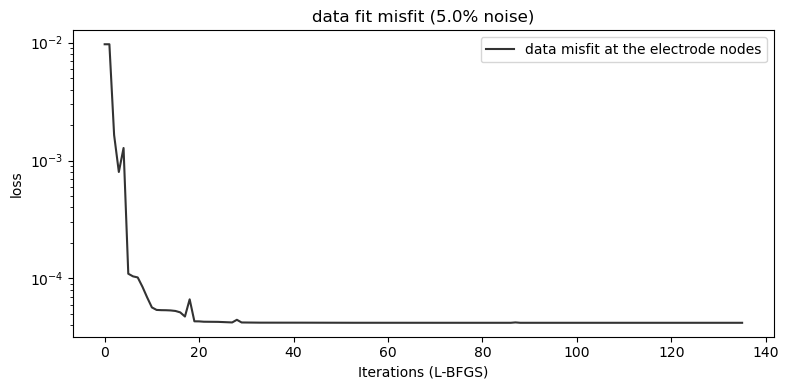

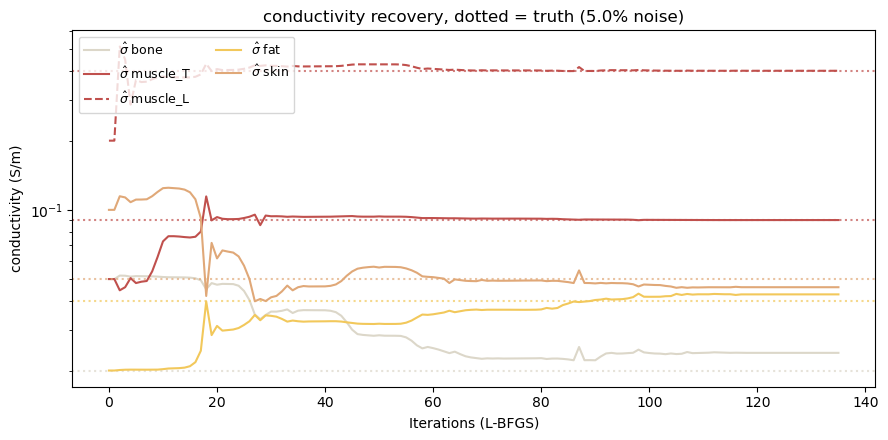

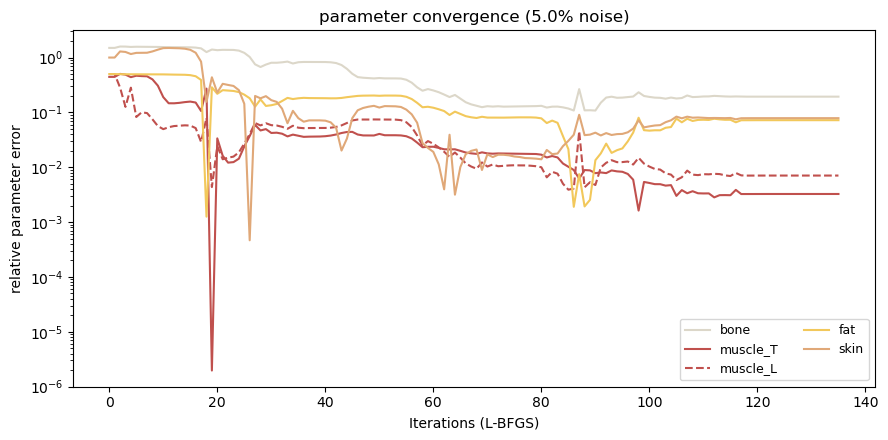

In [26]:
fig_loss, fig_sigma, fig_error = viz.plot_convergence(
    sigma_history, sigma_true, param_names,
    data_loss=data_loss_history, noise_percent=inv.noise_percent,
    reg_loss=reg_loss_history if inv.use_tikhonov else None,
    total_loss=loss_history if inv.use_tikhonov else None)

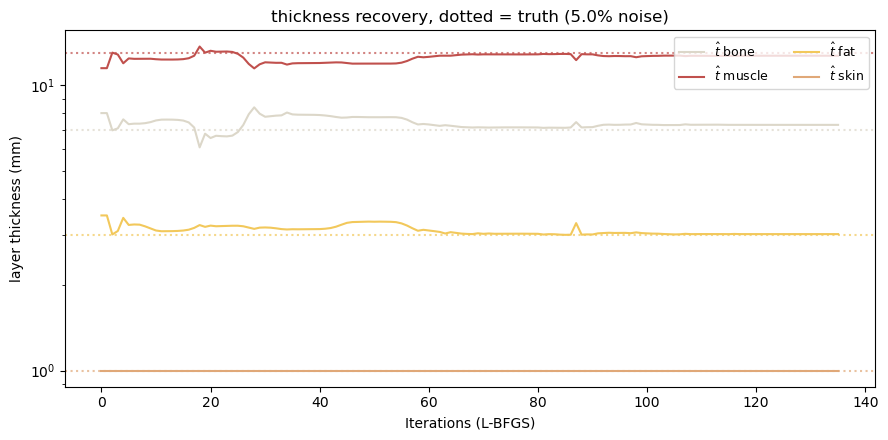

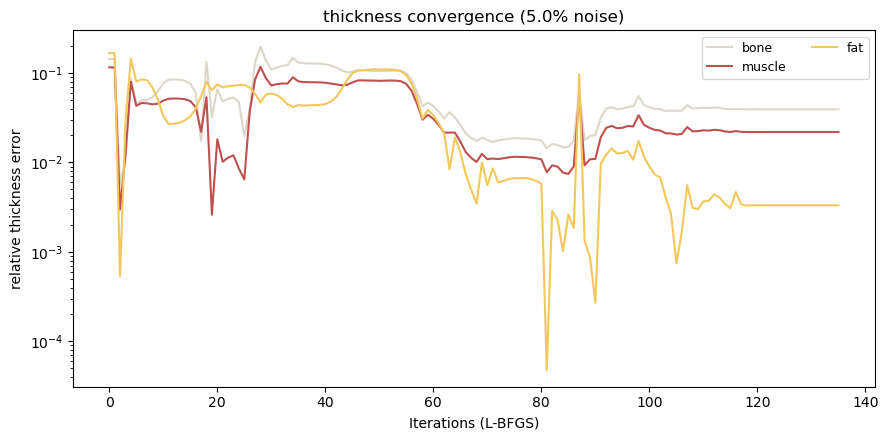

In [27]:
fig_thick, fig_thick_err = viz.plot_radius_convergence(
    interface_history, tissue.interfaces, tissue.layer_names,
    noise_percent=inv.noise_percent, limb_radius=LIMB_RADIUS_MM, unit="mm")

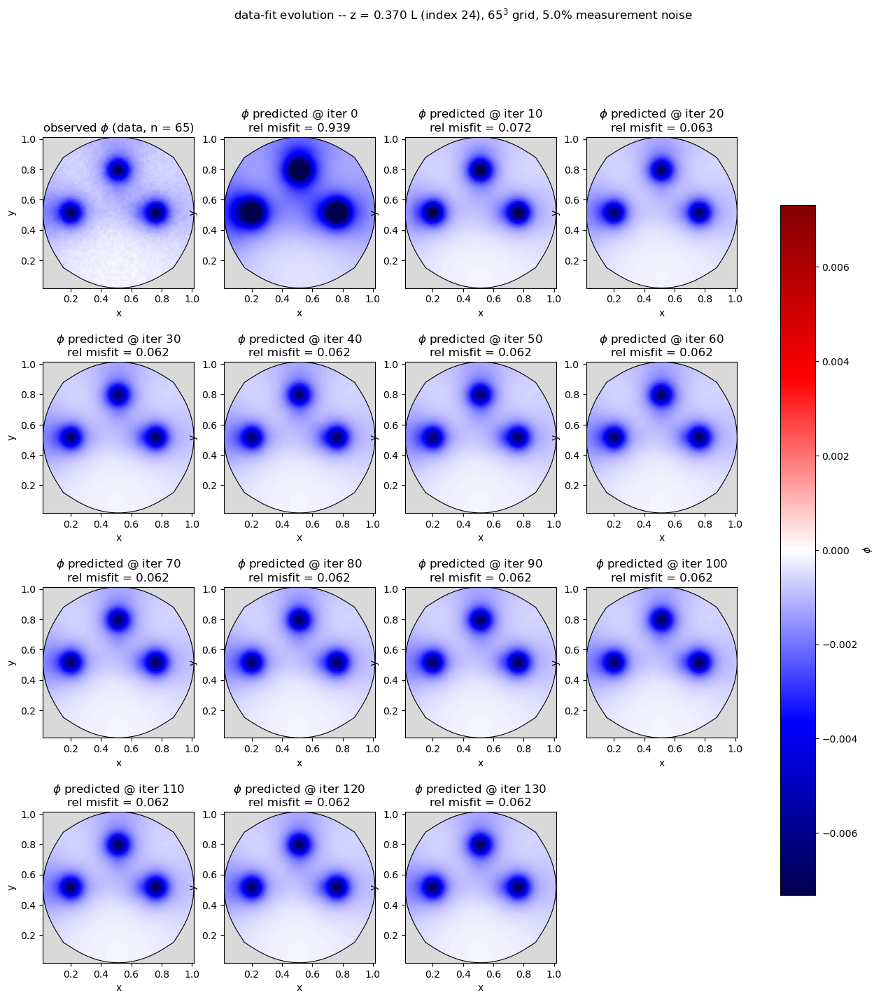

In [28]:
z_fraction = 0.37

fig_fields = viz.plot_field_panels(obs, phi_snapshots, z_fraction=z_fraction,
                                   noise_percent=inv.noise_percent)

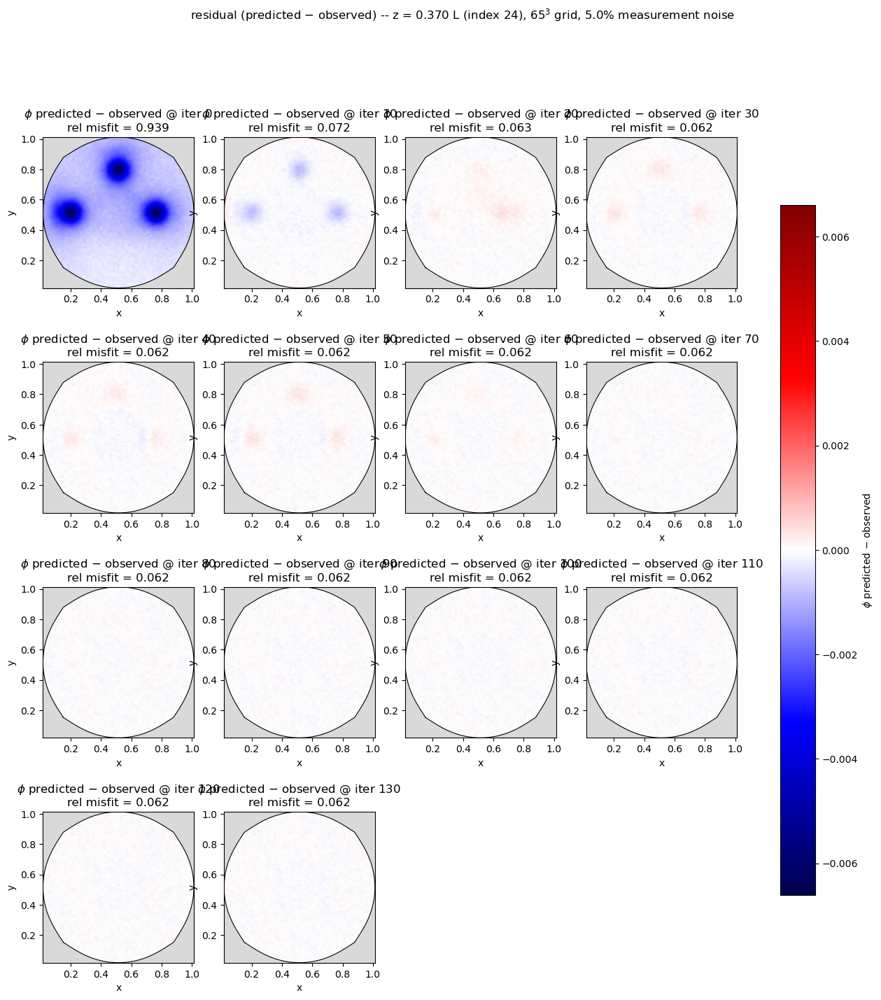

In [29]:
fig_residual = viz.plot_residual_panels(obs, phi_snapshots, z_fraction=z_fraction,
                                        noise_percent=inv.noise_percent)

136 iterates recorded, drawing every 7 -> 21 panels


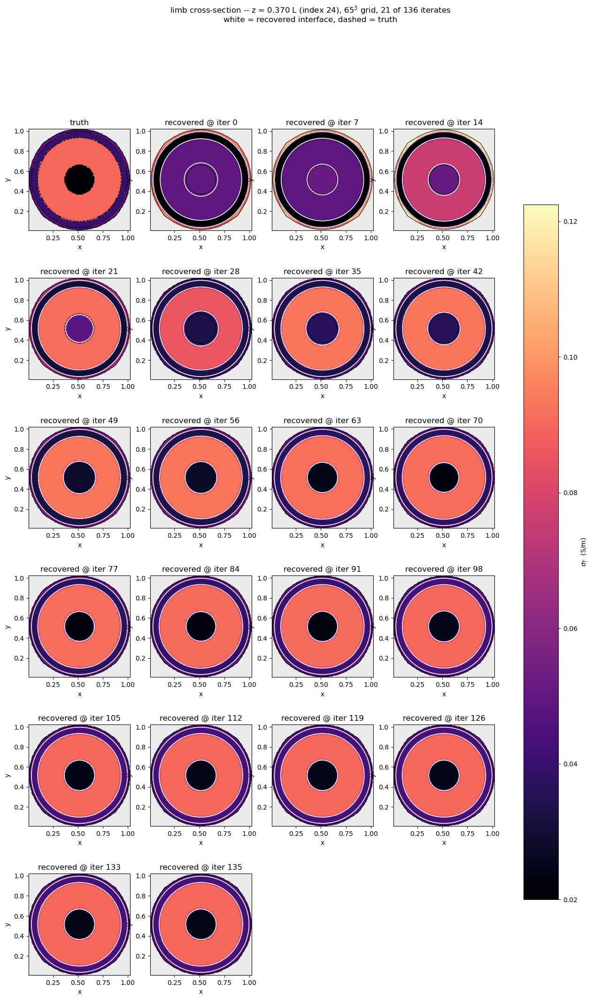

In [30]:
# every iterate was recorded (seven scalars each); thin here so the figure stays readable
geometry_every = max(1, -(-len(geometry_snapshots) // 20))

fig_geometry = viz.plot_geometry_panels(grid, tissue, geometry_snapshots, inv.epsilon,
                                        z_fraction=z_fraction,
                                        snapshot_every=geometry_every)

print(f"{len(geometry_snapshots)} iterates recorded, "
      f"drawing every {geometry_every} -> {1 + len(geometry_snapshots[::geometry_every])} panels")

In [31]:
print(f"\nmax relative error: conductivities "
      f"{max(abs(r - t) / t for r, t in zip(sigma_rec.tolist(), sigma_true.tolist())):.3e}, "
      f"thicknesses {max(abs(r - t) / t for r, t in zip(thicknesses_mm(R_rec).tolist(), thicknesses_mm(tissue.interfaces).tolist())):.3e}")


max relative error: conductivities 1.937e-01, thicknesses 3.919e-02


In [32]:
# Tikhonov sweep on the run above (hard labels, 5% noise). The observations are reused,
# so no data is regenerated; each lambda warm-starts from the previous solution, which is
# why this costs far less than seven cold runs.

LAMBDAS = [0.0, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4]
thick_true = thicknesses_mm(tissue.interfaces)


def run_lambda(lam, theta_start, max_iters=inv.max_iters):
    def penalised(theta_np):
        theta = torch.tensor(theta_np, dtype=torch.float64, requires_grad=True)
        sT_vec, sL_vec, R = unpack(theta)
        c = CoefficientHierarchy.from_vectors(gcfg, tissue, sT_vec, sL_vec,
                                              interfaces=R, epsilon=inv.epsilon)
        loss = sum(0.5 * ((forward(I, c, gcfg, solver) - o.phi)[mask_nodes] ** 2).sum()
                   for I, o in zip(sources, observations))
        loss = loss + 0.5 * lam * ((theta[:n_sigma] - rho_ref) ** 2).sum()
        loss.backward()
        return loss.item(), theta.grad.detach().numpy().copy()

    res = minimize(penalised, theta_start, jac=True, method="L-BFGS-B",
                   options={"maxiter": max_iters, "maxfun": 4 * max_iters,
                            "ftol": inv.ftol, "gtol": inv.gtol})

    theta_hat = torch.tensor(res.x)
    with torch.no_grad():
        sT_vec, sL_vec, R = unpack(theta_hat)
        c = CoefficientHierarchy.from_vectors(gcfg, tissue, sT_vec, sL_vec,
                                              interfaces=R, epsilon=inv.epsilon)
        data = float(sum(0.5 * ((forward(I, c, gcfg, solver) - o.phi)[mask_nodes] ** 2).sum()
                         for I, o in zip(sources, observations)))
    sig = theta_hat[:n_sigma].exp()
    thick = thicknesses_mm(interfaces_from_logits(theta_hat[n_sigma:], R_OUTER))
    return {"lam": lam, "x": res.x.copy(), "data": data,
            "norm": float((theta_hat[:n_sigma] - rho_ref).norm()),
            "sigma_err": ((sig - sigma_true).abs() / sigma_true).tolist(),
            "thick_err": ((thick - thick_true).abs() / thick_true).tolist(),
            "nit": res.nit, "nfev": res.nfev}


sweep = []
start = theta_ref.numpy()
for lam in LAMBDAS:
    print(f"lambda = {lam:.0e} ...", flush=True)
    sweep.append(run_lambda(lam, start))
    start = sweep[-1]["x"]                      # warm start the next one
    r = sweep[-1]
    print(f"   {r['nit']:3d} iterations | data misfit {r['data']:.4e} | "
          f"||rho - rho_ref|| {r['norm']:.4f} | "
          + "  ".join(f"{n} {v:.1%}" for n, v in zip(param_names, r["sigma_err"])))

lambda = 0e+00 ...


KeyboardInterrupt: 

In [ ]:
# Gradient check cell - could go before inversion step but we keep it at the end because it is easier to find

In [ ]:
# Autograd against central differences at the true parameters. This is the verification
# that backpropagating through the solver gives correct derivatives -- including the two
# logits, where the derivative is a shape derivative obtained with no hand-written adjoint.

FD_DELTA = 1e-4
check_labels = param_names + ["u_1", "u_2"]


def data_misfit(theta):
    sT_vec, sL_vec, R = unpack(theta)
    c = CoefficientHierarchy.from_vectors(gcfg, tissue, sT_vec, sL_vec,
                                          interfaces=R, epsilon=inv.epsilon)
    return sum(0.5 * ((forward(I, c, gcfg, solver) - o.phi)[mask] ** 2).sum()
               for I, o in zip(sources, observations))


theta_g = theta_true.clone().requires_grad_(True)
data_misfit(theta_g).backward()
g_auto = theta_g.grad.detach().clone()

print(f"{'parameter':>10s} {'autograd':>16s} {'central difference':>20s} {'rel. difference':>17s}")
for p, nm in enumerate(check_labels):
    tp, tm = theta_true.clone(), theta_true.clone()
    tp[p] += FD_DELTA
    tm[p] -= FD_DELTA
    with torch.no_grad():
        fd = float(data_misfit(tp) - data_misfit(tm)) / (2 * FD_DELTA)
    a = float(g_auto[p])
    print(f"{nm:>10s} {a:16.9e} {fd:20.9e} {abs(a - fd) / abs(fd):17.2e}")

In [ ]:
import json, pathlib

RESULTS = pathlib.Path("results-observation-design.json")
tag = ("superposition" if SUPERPOSE else "separate") + f"-{len(sources_sep)}src"
if R3 is not None:
    tag += f"-R3_{R3:.3f}"
n_elec = int(mask.sum()) * len(observations)

record = {
    "n_observations": len(observations),
    "n_electrodes": n_elec,
    "noise_seed": inv.noise_seed,
    "nit": int(result.nit),
    "final_grad": float(np.linalg.norm(result.jac)),
    "misfit_per_electrode": float(result.fun) / n_elec,
    "sigma_err": [abs(r - t) / t for r, t in zip(sigma_rec.tolist(), sigma_true.tolist())],
    "thick_err": [abs(r - t) / t for r, t in
                  zip(thicknesses_mm(R_rec).tolist(),
                      thicknesses_mm(tissue.interfaces).tolist())],
}

store = json.loads(RESULTS.read_text()) if RESULTS.exists() else {}
store[tag] = record
RESULTS.write_text(json.dumps(store, indent=1))
print(f"recorded '{tag}' at seed {inv.noise_seed}; file holds {sorted(store)}")

In [ ]:
store = json.loads(RESULTS.read_text())

if len(store) < 2:
    print(f"only {sorted(store)} recorded -- restart the kernel, flip SUPERPOSE, rerun")
else:
    a_, b_ = store["separate"], store["superposition"]
    print(f"{'':12s}{'separate':>14s}{'superposed':>14s}{'ratio':>9s}")
    for i, nm in enumerate(param_names):
        x, y = a_["sigma_err"][i], b_["sigma_err"][i]
        print(f"{nm:12s}{x:13.2%} {y:13.2%} {y / x:9.2f}")
    for i, nm in enumerate(tissue.layer_names[:-1]):
        x, y = a_["thick_err"][i], b_["thick_err"][i]
        print(f"{nm + ' thk':12s}{x:13.2%} {y:13.2%} {y / x:9.2f}")
    for k in ("n_electrodes", "nit", "misfit_per_electrode"):
        print(f"{k:12s}{a_[k]:14.4g}{b_[k]:14.4g}")